# BMI Projekt 1 - English
This notebook is for assistance with the coding for many of the questions in the project.
The sections are marked with the corresponding question in the Project description.
Remember, this code is provided to get started with the project, but the code is not complete for answering the corresponding questions

OBS: Im using Python 3.14.7

#### Initialize python packages

In [20]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import statsmodels.api as sm

#### Read data

In [21]:
# Path to data file
file_path = '/Users/talha/DTU/3 semester/Statistics/Project 1/bmi1/bmi1_data.csv'

# Load data
D = pd.read_csv(file_path, sep=';')

#### a) Simple summary of data


In [22]:
print("Dimensions of data frame (number of rows and columns): ", D.shape)
print("Column/variable names: ", D.columns)
print("First 5 rows of D:") # (\n means new line)
display(D.head())
print("Last 5 rows of D:")
display(D.tail())
print("Description of D:")
display(D.describe())
print("Types of variables:\n", D.dtypes)

Dimensions of data frame (number of rows and columns):  (145, 5)
Column/variable names:  Index(['height', 'weight', 'gender', 'urbanity', 'fastfood'], dtype='str')
First 5 rows of D:


,height,weight,gender,urbanity,fastfood
0,180,80,1,5,24.0
1,185,98,1,1,6.0
2,180,80,1,5,6.0
3,168,60,0,4,24.0
4,173,83,1,5,24.0


Last 5 rows of D:


,height,weight,gender,urbanity,fastfood
140,162,69,0,2,6.0
141,174,73,1,5,182.5
142,170,70,0,4,6.0
143,178,56,0,5,1.0
144,163,105,0,3,0.0


Description of D:


,height,weight,gender,urbanity,fastfood
count,145.000000,145.000000,145.000000,145.000000,145.000000
mean,173.903448,76.737931,0.503448,3.668966,21.037241
std,9.328365,15.208286,0.501721,1.374647,40.321484
min,154.000000,50.000000,0.000000,1.000000,0.000000
25%,166.000000,65.000000,0.000000,3.000000,6.000000
50%,173.000000,75.000000,1.000000,4.000000,6.000000
75%,182.000000,87.000000,1.000000,5.000000,24.000000
max,196.000000,130.000000,1.000000,5.000000,365.000000


Types of variables:
 height        int64
weight        int64
gender        int64
urbanity      int64
fastfood    float64
dtype: object


#### Calculate BMI

In [23]:
# Calculate BMI and add to data frame D
D['bmi'] = D['weight'] / (D['height']/100)**2

#### b) Histogram (Empirical density)

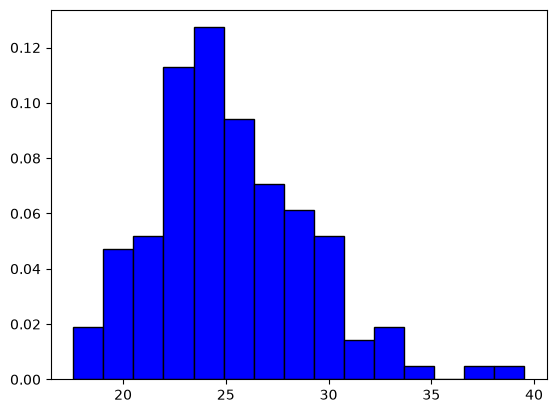

In [24]:
# Histogram describing the empirical density of BMI
# (histogram for BMI normalized so that the area is 1)
plt.hist(D['bmi'], bins = 15,density=True, color = 'blue', edgecolor = 'black')
plt.show()

#### Data subsets (men and women seperate)

In [25]:
# Split data into two sub data sets (men and women)
D_female = D[D['gender']==0]
D_male = D[D['gender']==1]

#### c) Density Histograms for Men and Women seperately

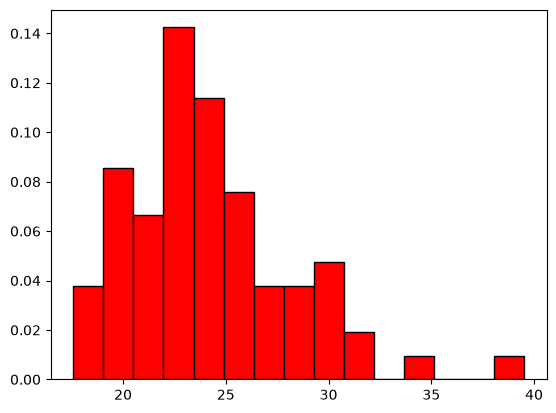

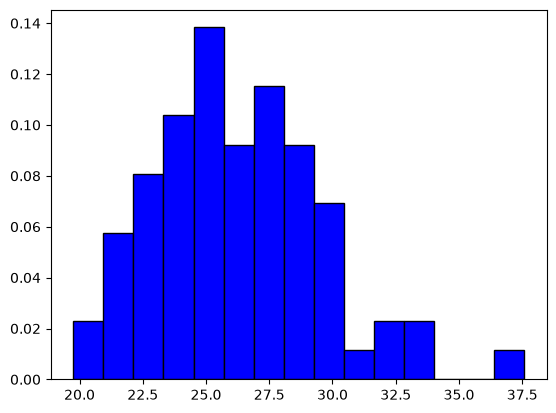

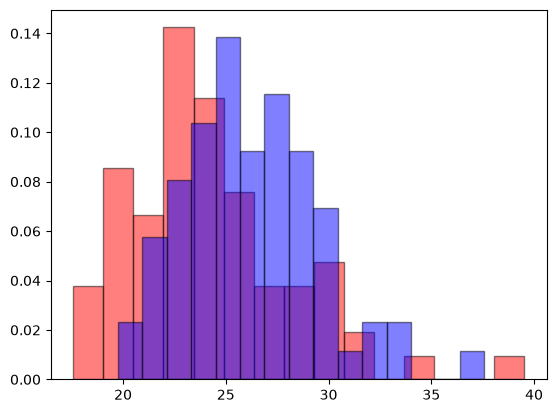

In [26]:
# Density histograms describing the empirical density of BMI for Women and Men

# Density histogram for women
plt.hist(D_female['bmi'], bins=15, density=True, color='red', edgecolor='black')
plt.show()

# Density histogram for men
plt.hist(D_male['bmi'], bins=15, density=True, color='blue', edgecolor='black')
plt.show()

# Combined in one plot
plt.hist(D_female['bmi'], bins = 15,density=True, color = 'red', edgecolor = 'black', alpha = 0.5)
plt.hist(D_male['bmi'], bins = 15,density=True, color = 'blue', edgecolor = 'black', alpha = 0.5)
plt.show()


#### d) Boxplot by genders

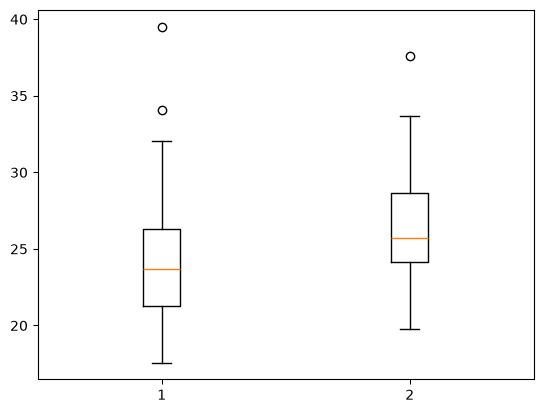

In [27]:
# Boxplot of BMI seperated into genders
plt.boxplot([D_female['bmi'], D_male['bmi']])
plt.show()

#### e) Key summary statistics for BMI

In [28]:
# Summary statistics for BMI for everyone and by gender
groups = {
    'Everyone': D['bmi'],
    'Women': D.loc[D['gender'] == 0, 'bmi'],
    'Men': D.loc[D['gender'] == 1, 'bmi'],
}

summary_rows = []
for group, bmi_values in groups.items():
    summary_rows.append({
        'Group': group,
        'n': bmi_values.count(),
        'Mean': bmi_values.mean(),
        'Variance': bmi_values.var(ddof=1),
        'Std. dev.': bmi_values.std(ddof=1),
        'Q1': bmi_values.quantile(0.25),
        'Median': bmi_values.median(),
        'Q3': bmi_values.quantile(0.75),
    })

summary = pd.DataFrame(summary_rows).set_index('Group')
display(summary.round(3))

,n,Mean,Variance,Std. dev.,Q1,Median,Q3
Group,,,,,,,
Everyone,145,25.248,14.686,3.832,22.590,24.691,27.636
Women,72,24.216,16.418,4.052,21.259,23.689,26.292
Men,73,26.265,11.069,3.327,24.152,25.726,28.634


#### f) QQ-plot for model validation

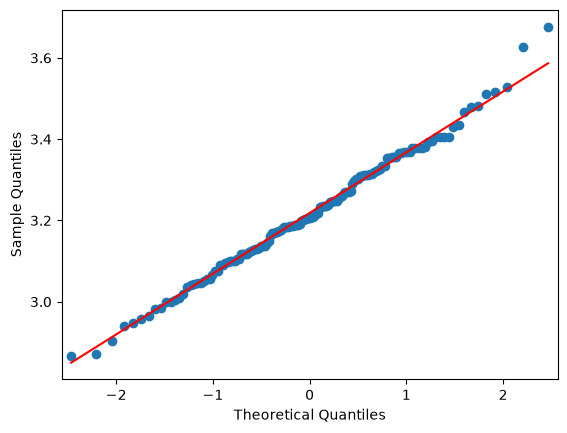

In [29]:
# New variable 'logbmi' with log-transformed BMI
D['logbmi'] = np.log(D['bmi'])

# QQ-plot for log-transformed BMI
sm.qqplot(D['logbmi'],line='q')
plt.show()



#### g-h) One-sample t-test

In [30]:
# T-test for one sample on log-transformed BMI
res = stats.ttest_1samp(D['logbmi'], popmean = np.log(25))
print("t-obs: ", res[0])
print("p-value: ", res[1])

# Confidence interval directly from t-test
print(res.confidence_interval())

t-obs:  -0.0999127408580046
p-value:  0.9205525650211787
ConfidenceInterval(low=np.float64(3.193202900926014), high=np.float64(3.242078180778501))


#### j) Confidence interval (CI) for mean and median

In [31]:
# Using sample for women only
D_female = D[D['gender']==0]
n = D_female.shape[0]
std_err = np.std(D_female['logbmi'],ddof=1)/np.sqrt(n)

# CI for mean of logBMI for women
KI = stats.t.interval(0.95, df=n-1, loc=D_female['logbmi'].mean(),scale=std_err)
print("95% CI for mean of logBMI for women: ", KI)

# Transform back to get CI for median BMI for women
print("95% CI for median BMI for women: ", np.exp(KI))

95% CI for mean of logBMI for women:  (np.float64(3.136525120167904), np.float64(3.2116686703449284))
95% CI for median BMI for women:  [23.02372302 24.82046887]


#### k) Welch t-test

In [32]:
# Comparison of logBMI for women and men
D_male = D[D['gender'] == 1]
res = stats.ttest_ind(D_female['logbmi'],D_male['logbmi'], equal_var=False)
print("t-obs: ", res[0])
print("p-value: ", res[1])

t-obs:  -3.6374526305970956
p-value:  0.00039196478151182185


#### m) Correlation

In [33]:
# Correlation between chosen variables
print(D[['weight', 'fastfood', 'bmi']].corr())

            weight  fastfood       bmi
weight    1.000000  0.279322  0.828261
fastfood  0.279322  1.000000  0.153158
bmi       0.828261  0.153158  1.000000


## EXTRA

#### Subsets in Python

In [34]:
## Extra information about picking out subsets in Python
#
# Logical vector with TRUE or FALSE for every value in a column in D,
# for example: Find all women in the dataframe
women = D['gender'] == 0
print("Logical vector: \n", women)
# This logical vector can then be used to pick out all women (values where women = TRUE)
print("Using logical vector:")
display(D[women])
# Alternatively you can use the pandas function .loc
print("Using .loc:")
display(D.loc[D['gender'] == 0, :]) # ":" means all columns
# More complex logical expressions kan be used, for example:
# Find all women under 55 kg:
print("Women under 55 kg:")
women_under_55kg = (D['gender'] == 0) & (D['weight'] < 55)
display(D[women_under_55kg])

## DISPLAY function gives a nicer table than print. This is especially useful when we 
# are working with dataframes (pandas)

Logical vector: 
 0      False
1      False
2      False
3       True
4      False
       ...  
140     True
141    False
142     True
143     True
144     True
Name: gender, Length: 145, dtype: bool
Using logical vector:


,height,weight,gender,urbanity,fastfood,bmi,logbmi
3,168,60,0,4,24.0,21.258503,3.056757
5,161,78,0,3,6.0,30.091432,3.404240
6,168,82,0,2,6.0,29.053288,3.369132
7,166,58,0,2,24.0,21.048048,3.046808
9,172,52,0,1,6.0,17.577069,2.866595
...,...,...,...,...,...,...,...
136,167,65,0,5,6.0,23.306680,3.148740
140,162,69,0,2,6.0,26.291724,3.269254
142,170,70,0,4,6.0,24.221453,3.187239
143,178,56,0,5,1.0,17.674536,2.872125


Using .loc:


,height,weight,gender,urbanity,fastfood,bmi,logbmi
3,168,60,0,4,24.0,21.258503,3.056757
5,161,78,0,3,6.0,30.091432,3.404240
6,168,82,0,2,6.0,29.053288,3.369132
7,166,58,0,2,24.0,21.048048,3.046808
9,172,52,0,1,6.0,17.577069,2.866595
...,...,...,...,...,...,...,...
136,167,65,0,5,6.0,23.306680,3.148740
140,162,69,0,2,6.0,26.291724,3.269254
142,170,70,0,4,6.0,24.221453,3.187239
143,178,56,0,5,1.0,17.674536,2.872125


Women under 55 kg:


,height,weight,gender,urbanity,fastfood,bmi,logbmi
9,172,52,0,1,6.0,17.577069,2.866595
24,157,50,0,2,0.0,20.284799,3.009872
45,161,53,0,3,6.0,20.446742,3.017824
66,172,54,0,3,6.0,18.253110,2.904335


#### Additional Python tips

In [35]:
## Make a for-loop for calculating some summary statistics
## and save in a new dataframe
Tbl = pd.DataFrame()
for i in [0,1]:
    Tbl.loc[i, "mean"] = D[D['gender'] == i]['bmi'].mean()
    Tbl.loc[i, "var"] = D[D['gender'] == i]['bmi'].var()

Tbl.index = ['Women', 'Men'] # Nameing rows

# show Tbl (dataframe)
display(Tbl)


,mean,var
Women,24.216402,16.417873
Men,26.265363,11.068725


In [36]:
# There are many ways to reach the same restults, and some have more compact commands/functions:
# For example:
result = D.groupby('gender')['bmi'].agg(['mean', 'var'])
# Here the groupby function is used to group the data by gender, and then the agg (aggregate) function
# for calculating mean and variance for BMI for each group.
display(result)

# See more functions in pandas documentation: https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.html
# Numpy documentation: https://numpy.org/doc/stable/reference/index.html
# Or find documentation/guides for other python packages/functions online.


,mean,var
gender,,
0,24.216402,16.417873
1,26.265363,11.068725


#### Latex Tips
Pandas (pd) also includes a function that is very handy for writing tables/dataframes directly into Latex-code. 
This is done by usind the function `pd.to_latex()`.
The following is the simplest form of the function:

In [ ]:
Tbl_latex = Tbl.to_latex()
print(Tbl_latex)

Women: n=72, mean log-BMI=3.174097, SD=0.159888, 95% CI mean log-BMI=(3.136525, 3.211669), 95% CI median BMI=(23.023723, 24.820469)
Men: n=73, mean log-BMI=3.260588, SD=0.123911, 95% CI mean log-BMI=(3.231677, 3.289498), 95% CI median BMI=(25.322087, 26.829402)
Welch degrees of freedom=133.750107


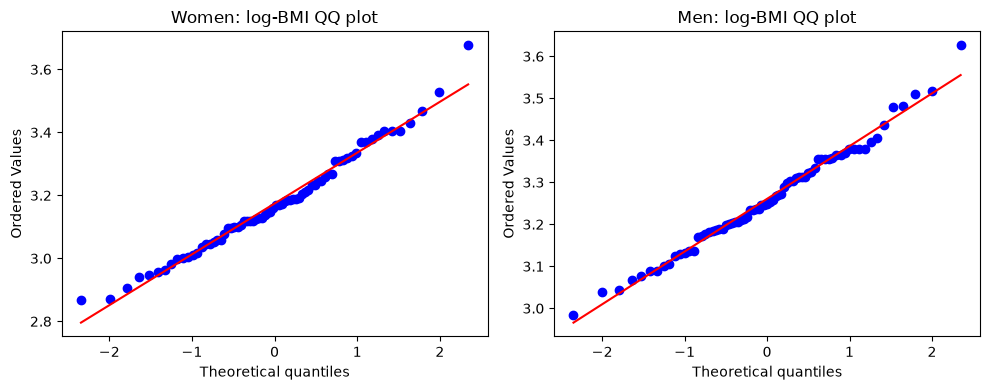

Correlation matrix (BMI, weight, fast-food):
             bmi  weight  fastfood
bmi       1.0000  0.8283    0.1532
weight    0.8283  1.0000    0.2793
fastfood  0.1532  0.2793    1.0000


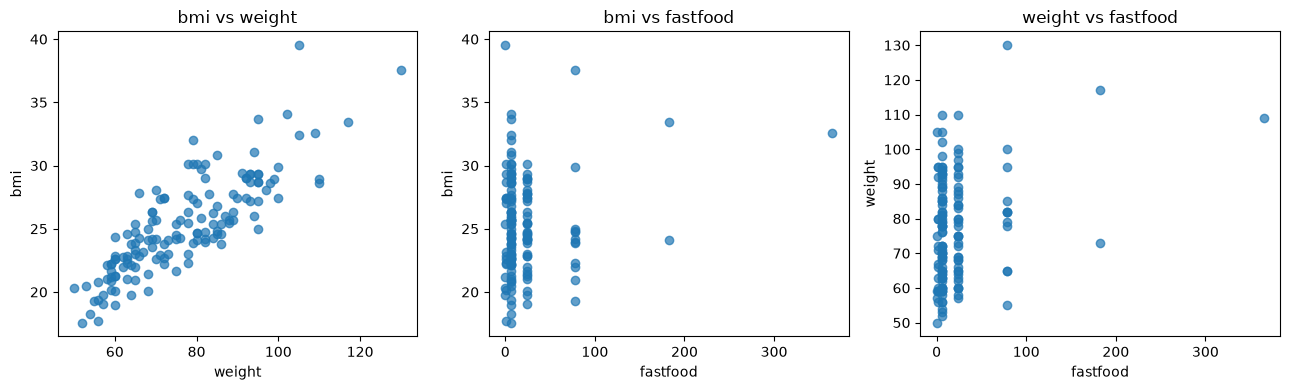

In [ ]:
# Separate normal models for log-BMI by gender, confidence intervals, and model checks
D_w = D[D['gender'] == 0]
D_m = D[D['gender'] == 1]
y_w = D_w['logbmi']
y_m = D_m['logbmi']
for label, y in [('Women', y_w), ('Men', y_m)]:
    n = len(y)
    mean = y.mean()
    sd = y.std(ddof=1)
    ci = stats.t.interval(0.95, df=n-1, loc=mean, scale=sd/np.sqrt(n))
    print(f'{label}: n={n}, mean log-BMI={mean:.6f}, SD={sd:.6f}, 95% CI mean log-BMI=({ci[0]:.6f}, {ci[1]:.6f}), 95% CI median BMI=({np.exp(ci[0]):.6f}, {np.exp(ci[1]):.6f})')

# Welch-Satterthwaite degrees of freedom
nw, nm = len(y_w), len(y_m)
vw, vm = y_w.var(ddof=1), y_m.var(ddof=1)
df_welch = (vw/nw + vm/nm)**2 / ((vw/nw)**2/(nw-1) + (vm/nm)**2/(nm-1))
print(f'Welch degrees of freedom={df_welch:.6f}')

# QQ plots for the two fitted normal models
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, label, y in zip(axes, ['Women', 'Men'], [y_w, y_m]):
    stats.probplot(y, dist='norm', plot=ax)
    ax.set_title(f'{label}: log-BMI QQ plot')
plt.tight_layout()
plt.show()

# Pairwise correlations and scatter plots
vars3 = D[['bmi', 'weight', 'fastfood']]
print('Correlation matrix (BMI, weight, fast-food):')
print(vars3.corr().round(4))
pairs = [('weight', 'bmi'), ('fastfood', 'bmi'), ('fastfood', 'weight')]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (x, y) in zip(axes, pairs):
    ax.scatter(D[x], D[y], alpha=0.7)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(f'{y} vs {x}')
plt.tight_layout()
plt.show()